# Appliances Energy Prediction — Stage 2: Recurrent models, TCN and HPO

**Group 9 · AISE 4010 Course Project · Stage 2 (Lab 9)**

Stage 2 extends the Stage 1 comparison (naive / seasonal naive / Ridge / MLP / CNN) with **RNN, LSTM, GRU and TCN** models, all trained under one controlled protocol, followed by a pre-declared two-stage hyperparameter search and a validation-only model selection. The selected finalist and its preprocessing state are checkpointed before the test set is used.

## What changed since Stage 1 and why
Stage 1 showed that at the native 10-minute resolution **no model beat the naive last-value forecast on MAE** (naive 26.65 Wh vs best network 31.58 Wh). The target is dominated by short random spikes, so "repeat the last value" is nearly optimal for MAE. For Stage 2 we revisited the target definition (§3 shows the validation-only evidence):

| Item | Stage 1 | **Stage 2** | Reason |
|---|---|---|---|
| Target | `Appliances`, Wh per 10 min | **Next-hour appliance energy, Wh/h** (sum of the six 10-min readings) | Hourly totals smooth unpredictable sub-hour spikes and are the resolution at which load is usually scheduled/billed |
| Frequency | Native 10 min | **Resampled to 1 h** (energy columns summed, state columns averaged, partial bins dropped) | Weather inputs are natively hourly (interpolated to 10 min by the dataset authors), so 1 h removes the artificial interpolation |
| Target transform | None (standardised Wh) | **log1p, then standardised**; every metric is computed after inverting back to Wh | Hourly target is right-skewed (skew ≈ 2.3); log scale makes errors relative; it roughly tripled the linear probe's MAE gain over naive (≈10% vs ≈3%) and was the only design to beat naive clearly on both MAE and RMSE |
| Loss | Huber (δ=1, behaved like MSE) | **L1 on the standardised log target** (Huber considered in HPO) | Matches the MAE selection metric (Stage 1 follow-up) |
| Horizon | 1 step (10 min) | **1 step (1 h)**, `HORIZON` still configurable | Same single-step contract |
| Lookback | 18 / 36 / 72 steps (3–12 h) | **6 / 12 / 24 h** (3 h added in HPO) | Stage 1's best window was at the short edge of the grid |
| Split, leakage rules, baselines, metrics | 60/20/20 chronological, fit-on-train, lagged-only weather | **Unchanged** | Same evaluation contract |

> Stage 1 numbers (Wh per 10 min) are **not** directly comparable with Stage 2 numbers (Wh per hour). The comparable quantity across stages is the **% improvement over the naive baseline**.

## 0. Setup and configuration

In [5]:
import os, time, json, random, itertools, platform, pickle, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch, torch.nn as nn
import sklearn
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 220, "display.max_columns", 60)

# ---------------- CONFIG (identical for every model) ----------------
QUICK = os.environ.get("QUICK", "0") == "1"       # smoke-test mode: tiny grids, few epochs
SEED = 42
FREQ, STEPS_PER_BIN = "1h", 6                      # resample 10-min data to hourly; a full bin has 6 readings
HORIZON = 1                                        # predict y[t+HORIZON] (hours) from the window ending at t
LOOKBACKS = [6, 12, 24]                            # Stage-A screening windows (hours)
LOOKBACKS_B = [3, 6, 12, 24]                       # Stage-B (finalist HPO) windows
MAXW = max(LOOKBACKS + LOOKBACKS_B)                # fixed -> identical target instances for every window/model
TRAIN_FRAC, VAL_FRAC = 0.60, 0.20
MAX_EPOCHS, PATIENCE, CLIP = 150, 15, 1.0          # early stopping on validation loss; grad-norm clipping for all models
DEFAULTS = dict(dropout=0.2, lr=1e-3, batch=64, wd=1e-5, loss="L1")   # shared training settings unless HPO overrides
SCREEN_SEEDS = [42, 43]                            # every HPO configuration is scored as the mean over these seeds
FINAL_SEEDS = [42, 43, 44, 45, 46]
N_TRIALS_B = 30                                    # Stage-B budget (trials) for the selected family
DAY, WEEK = 24, 168                                # in hourly steps
if QUICK:
    MAX_EPOCHS, PATIENCE, SCREEN_SEEDS, FINAL_SEEDS, N_TRIALS_B = 4, 2, [42], [42, 43], 3

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)
    torch.backends.cudnn.deterministic = True; torch.backends.cudnn.benchmark = False
def sync():
    if DEVICE.type == "cuda": torch.cuda.synchronize()
set_seed(SEED)
for d in ("results_stage2", "checkpoints"): os.makedirs(d, exist_ok=True)
ENV = dict(python=platform.python_version(), torch=torch.__version__, sklearn=sklearn.__version__,
           numpy=np.__version__, pandas=pd.__version__, device=str(DEVICE),
           gpu=torch.cuda.get_device_name(0) if torch.cuda.is_available() else None, quick=QUICK)
print(ENV)

def metrics(y_true, y_pred):
    err = np.asarray(y_pred, dtype=float) - np.asarray(y_true, dtype=float)
    return dict(MAE=np.mean(np.abs(err)), RMSE=np.sqrt(np.mean(err**2)),
                sMAPE=100*np.mean(2*np.abs(err)/(np.abs(y_true)+np.abs(y_pred)+1e-8)),
                R2=1-np.sum(err**2)/np.sum((y_true-np.mean(y_true))**2))

{'python': '3.12.2', 'torch': '2.15.0+cpu', 'sklearn': '1.9.1', 'numpy': '2.5.5', 'pandas': '3.1.1', 'device': 'cpu', 'gpu': None, 'quick': False}


## 1. Data loading, audit and hourly resampling
The 10-minute audit from Stage 1 is repeated briefly, then the series is resampled to hourly bins `[h:00, h:50]` (left-labelled, left-closed):
* **Energy columns** (`Appliances`, `lights`) are **summed** → Wh per hour.
* **State columns** (temperatures, humidities, weather, `rv1`, `rv2`) are **averaged**.
* Bins with fewer than 6 readings are dropped (only the final bin, 2016-05-27 18:00, which holds one reading).

In [6]:
CSV = "energydata_complete.csv"
if not os.path.exists(CSV):
    try:
        from google.colab import files
        print("Please upload energydata_complete.csv"); files.upload()
    except ImportError:
        raise FileNotFoundError("Place energydata_complete.csv next to this notebook.")
df = pd.read_csv(CSV, parse_dates=["date"]).sort_values("date").reset_index(drop=True)
d10 = df["date"].diff().dropna()
print(f"10-min data: {len(df)} rows, {df.date.min()} -> {df.date.max()}, gaps={(d10 != pd.Timedelta(minutes=10)).sum()}, "
      f"dup timestamps={df.date.duplicated().sum()}, missing={df.isna().sum().sum()}")

ENERGY = ["Appliances", "lights"]
STATE = [c for c in df.columns if c not in ["date"] + ENERGY]
g = df.set_index("date").resample(FREQ, label="left", closed="left")
cnt = g["Appliances"].count()
dh_all = pd.concat([g[ENERGY].sum(), g[STATE].mean()], axis=1)[[c for c in df.columns if c != "date"]]
partial = cnt[cnt != STEPS_PER_BIN]
dh = dh_all[cnt == STEPS_PER_BIN].reset_index()
n = len(dh)
dh_diffs = dh["date"].diff().dropna()
audit = pd.Series({
    "Source": "UCI ML Repository — Appliances Energy Prediction (Candanedo et al., 2017)",
    "Target": "Appliances energy in the next hour (sum of six 10-min readings), Wh/h",
    "Resampling rule": "1 h, left-closed/left-labelled; energy=sum, states=mean; drop bins with <6 readings",
    "Partial bins dropped": f"{len(partial)}  {[(str(k), int(v)) for k, v in partial.items()]}",
    "Coverage": f"{dh.date.min()}  →  {dh.date.max()}",
    "Hourly rows": n,
    "Gaps (steps != 1 h)": int((dh_diffs != pd.Timedelta(hours=1)).sum()),
    "Duplicated timestamps": int(dh.date.duplicated().sum()),
    "Missing values": int(dh.isna().sum().sum()),
    "Energy conserved (sum Wh)": f"{dh.Appliances.sum():,.0f} of {df.Appliances.sum():,.0f} (difference = dropped partial bin)",
})
display(audit.to_frame("value"))
assert (dh_diffs == pd.Timedelta(hours=1)).all(), "hourly series must be regular"
display(dh[["Appliances", "lights", "T1", "T_out", "RH_out"]].describe().T.round(2))

10-min data: 19735 rows, 2016-01-11 17:00:00 -> 2016-05-27 18:00:00, gaps=0, dup timestamps=0, missing=0


,value
Source,UCI ML Repository — Appliances Energy Predicti...
Target,Appliances energy in the next hour (sum of six...
Resampling rule,"1 h, left-closed/left-labelled; energy=sum, st..."
Partial bins dropped,"1 [('2016-05-27 18:00:00', 1)]"
Coverage,2016-01-11 17:00:00 → 2016-05-27 17:00:00
Hourly rows,3289
Gaps (steps != 1 h),0
Duplicated timestamps,0
Missing values,0
Energy conserved (sum Wh),"1,927,580 of 1,928,010 (difference = dropped p..."


,count,mean,std,min,25%,50%,75%,max
Appliances,3289.0,586.07,486.11,170.00,300.00,380.00,660.00,3650.00
lights,3289.0,22.81,41.40,0.00,0.00,0.00,20.00,310.00
T1,3289.0,21.69,1.60,16.79,20.74,21.60,22.63,26.20
T_out,3289.0,7.41,5.31,-4.96,3.67,6.92,10.41,25.93
RH_out,3289.0,79.75,14.83,25.25,70.42,83.67,91.58,100.00


## 2. Target-design study (validation data only)
Before committing to a target, we compared candidate designs with a cheap, deterministic **linear probe**: Ridge on flattened lagged inputs + target-time calendar features, α chosen on validation, compared against the naive last-value forecast **on the validation split only**. The test split is not read in this section. Each resolution uses its own 60/20/20 chronological split (boundaries differ by < 1 h).

Table 1 — the question is: *for which target does any learned model have signal beyond persistence?*

Table 1 — Target-design probe (validation only; improvement of Ridge over naive)


,Target design,window,log1p,n_val,naive val MAE,Ridge val MAE,MAE impr. %,naive val RMSE,Ridge val RMSE,RMSE impr. %
0,10-min Wh (Stage 1),18,False,3947,28.42,29.77,-4.75,71.96,65.78,8.58
1,"10-min Wh, log1p",18,True,3947,28.42,31.03,-9.16,71.96,82.53,-14.69
2,Hourly Wh,6,False,658,229.04,221.20,3.42,433.31,371.75,14.21
3,Hourly Wh,24,False,658,229.04,245.35,-7.12,433.31,392.48,9.42
4,"Hourly Wh, log1p",6,True,658,229.04,205.06,10.47,433.31,392.57,9.40
5,"Hourly Wh, log1p",24,True,658,229.04,213.32,6.87,433.31,387.09,10.67


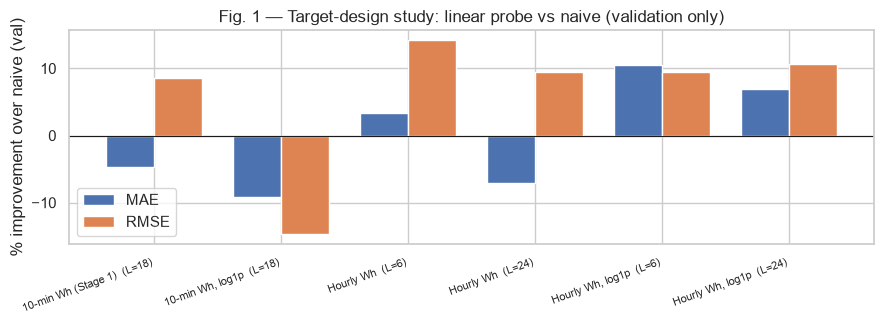

In [7]:
def probe(frame, L, season, log, label):
    y = frame["Appliances"].values.astype(float); n_ = len(y)
    a, b = int(TRAIN_FRAC*n_), int((TRAIN_FRAC+VAL_FRAC)*n_)
    Xo = frame.drop(columns=["date", "rv1", "rv2"]).values.astype(float)
    Xo = StandardScaler().fit(Xo[:a]).transform(Xo)
    ts_ = frame["date"]; hr_ = ts_.dt.hour + ts_.dt.minute/60; dw_ = ts_.dt.dayofweek
    Cc = np.column_stack([np.sin(2*np.pi*hr_/24), np.cos(2*np.pi*hr_/24), np.sin(2*np.pi*dw_/7), np.cos(2*np.pi*dw_/7), dw_ >= 5]).astype(float)
    yt = np.log1p(y) if log else y
    sc = StandardScaler().fit(yt[:a, None]); ys_ = sc.transform(yt[:, None]).ravel()
    T_ = np.arange(max(L, season), n_); tr_, va_ = T_[T_ < a], T_[(T_ >= a) & (T_ < b)]
    W = lambda idx: np.hstack([Xo[idx[:, None] - 1 - np.arange(L)].reshape(len(idx), -1), Cc[idx]])
    best = None
    for alpha in [1, 10, 100, 1000]:
        p = sc.inverse_transform(Ridge(alpha=alpha).fit(W(tr_), ys_[tr_]).predict(W(va_))[:, None]).ravel()
        p = np.expm1(p) if log else p
        m = metrics(y[va_], p)
        if best is None or m["MAE"] < best[0]["MAE"]: best = (m, alpha)
    nv = metrics(y[va_], y[va_ - 1])
    return {"Target design": label, "window": L, "log1p": log, "n_val": len(va_),
            "naive val MAE": nv["MAE"], "Ridge val MAE": best[0]["MAE"], "MAE impr. %": 100*(nv["MAE"]-best[0]["MAE"])/nv["MAE"],
            "naive val RMSE": nv["RMSE"], "Ridge val RMSE": best[0]["RMSE"], "RMSE impr. %": 100*(nv["RMSE"]-best[0]["RMSE"])/nv["RMSE"]}

study = pd.DataFrame([
    probe(df, 18, 144, False, "10-min Wh (Stage 1)"),
    probe(df, 18, 144, True,  "10-min Wh, log1p"),
    probe(dh, 6, 24, False,   "Hourly Wh"),
    probe(dh, 24, 24, False,  "Hourly Wh"),
    probe(dh, 6, 24, True,    "Hourly Wh, log1p"),
    probe(dh, 24, 24, True,   "Hourly Wh, log1p"),
])
study.to_csv("results_stage2/table1_target_study.csv", index=False)
print("Table 1 — Target-design probe (validation only; improvement of Ridge over naive)")
display(study.round(2))

fig, ax = plt.subplots(figsize=(9, 3.4))
lab = study["Target design"] + "  (L=" + study.window.astype(str) + ")"
x = np.arange(len(study)); w = 0.38
ax.bar(x - w/2, study["MAE impr. %"], w, label="MAE"); ax.bar(x + w/2, study["RMSE impr. %"], w, label="RMSE")
ax.axhline(0, color="k", lw=0.8); ax.set_xticks(x); ax.set_xticklabels(lab, rotation=20, ha="right", fontsize=8)
ax.set_ylabel("% improvement over naive (val)"); ax.set_title("Fig. 1 — Target-design study: linear probe vs naive (validation only)"); ax.legend()
plt.tight_layout(); plt.savefig("results_stage2/fig1_target_study.png", dpi=150); plt.show()

**Decision.** At 10-min resolution the probe loses to naive on MAE with or without a log transform, reproducing the Stage 1 finding. Hourly aggregation alone helps RMSE a lot but gives only a marginal MAE gain (+3% at 6 h, and a loss at 24 h). **Hourly + log1p** gives the largest MAE gain (≈10%) while keeping a ≈9–11% RMSE gain, i.e. a learned model clearly beats persistence on *both* metrics, so it is the Stage 2 target for every model. Short windows (6 h) beat 24 h for the linear probe, consistent with Stage 1. This choice was made on validation data only.

## 3. Chronological split (hourly)
Same 60/20/20 rule as Stage 1, applied to hourly rows. A sample is indexed by its **target hour** `i`; its input window ends at `i − HORIZON`. Training targets start at `MAXW + HORIZON − 1` so that every window length uses **identical** target instances.

Table 2 — Chronological split (hourly samples)


,split,first_target,last_target,n_samples,days,share_pct
0,train,2016-01-12 17:00:00,2016-04-02 21:00:00,1949,81.2,59.3
1,val,2016-04-02 22:00:00,2016-04-30 07:00:00,658,27.4,20.0
2,test,2016-04-30 08:00:00,2016-05-27 17:00:00,658,27.4,20.0


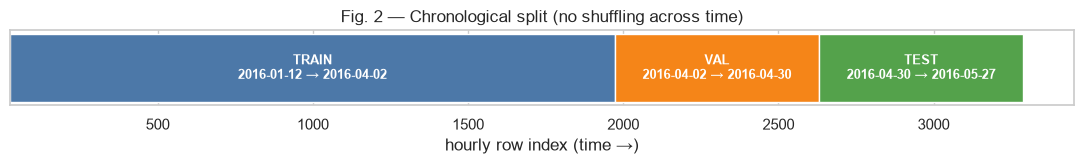

In [8]:
n_train = int(TRAIN_FRAC * n); n_val_end = int((TRAIN_FRAC + VAL_FRAC) * n)
splits = {"train": (MAXW + HORIZON - 1, n_train), "val": (n_train, n_val_end), "test": (n_val_end, n)}
split_table = pd.DataFrame([dict(split=k, first_target=dh.date[lo], last_target=dh.date[hi-1], n_samples=hi-lo,
                                 days=round((hi-lo)/24, 1), share_pct=round(100*(hi-lo)/n, 1)) for k, (lo, hi) in splits.items()])
print("Table 2 — Chronological split (hourly samples)"); display(split_table)

cols = {"train": "#4C78A8", "val": "#F58518", "test": "#54A24B"}
fig, ax = plt.subplots(figsize=(11, 1.8))
for k, (lo, hi) in splits.items():
    ax.barh(0, hi-lo, left=lo, color=cols[k], edgecolor="white")
    ax.text((lo+hi)/2, 0, f"{k.upper()}\n{dh.date[lo].date()} → {dh.date[hi-1].date()}", ha="center", va="center", color="white", fontsize=9, fontweight="bold")
ax.set_yticks([]); ax.set_xlabel("hourly row index (time →)"); ax.set_title("Fig. 2 — Chronological split (no shuffling across time)")
plt.tight_layout(); plt.savefig("results_stage2/fig2_split.png", dpi=150); plt.show()

## 4. Exploratory analysis of the hourly target
Figures are descriptive; anything that informs a decision (feature drop, transform) uses **training rows only**.

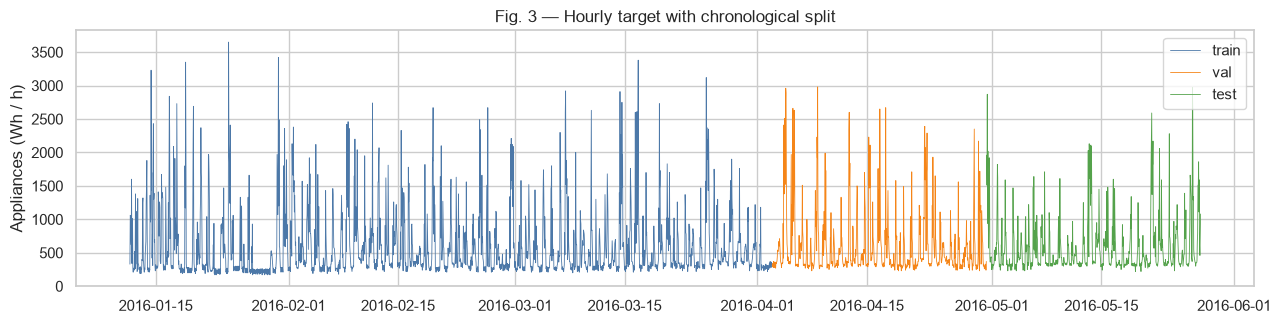

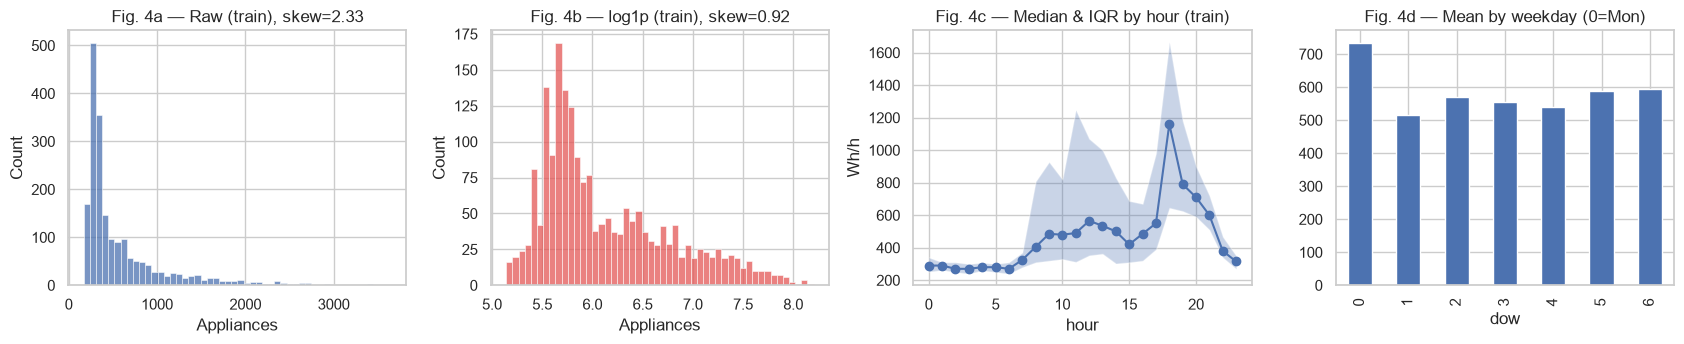

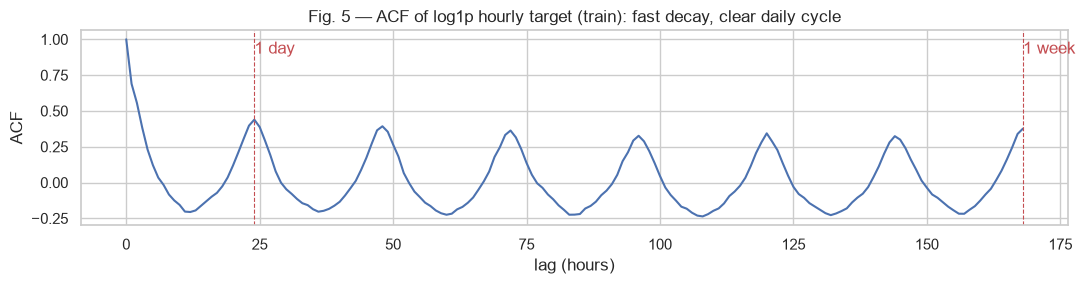

ACF at lags 1,2,3,6,12,24,48,168 h: [ 0.689  0.556  0.383  0.034 -0.206  0.439  0.393  0.376]


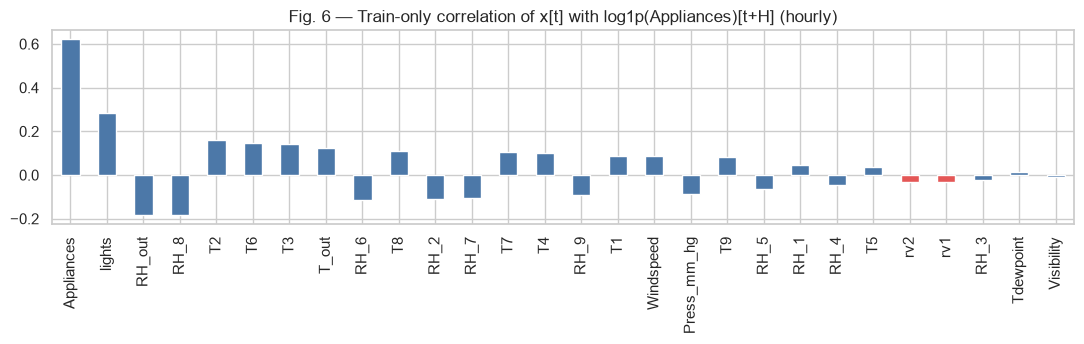

rv1/rv2 train corr: {'rv1': -0.0339, 'rv2': -0.0339} 
Dropped ['rv1', 'rv2']; kept 26 observed series


In [9]:
fig, ax = plt.subplots(figsize=(13, 3.4))
for k, (lo, hi) in {"train": (0, n_train), "val": (n_train, n_val_end), "test": (n_val_end, n)}.items():
    ax.plot(dh.date[lo:hi], dh.Appliances[lo:hi], lw=0.6, color=cols[k], label=k)
ax.set_ylabel("Appliances (Wh / h)"); ax.set_title("Fig. 3 — Hourly target with chronological split"); ax.legend()
plt.tight_layout(); plt.savefig("results_stage2/fig3_series.png", dpi=150); plt.show()

tr = dh.iloc[:n_train].copy(); tr["hour"] = tr.date.dt.hour; tr["dow"] = tr.date.dt.dayofweek
fig, axs = plt.subplots(1, 4, figsize=(17, 3.6))
sns.histplot(tr.Appliances, bins=50, ax=axs[0]); axs[0].set_title(f"Fig. 4a — Raw (train), skew={tr.Appliances.skew():.2f}")
sns.histplot(np.log1p(tr.Appliances), bins=50, ax=axs[1], color="#E45756"); axs[1].set_title(f"Fig. 4b — log1p (train), skew={np.log1p(tr.Appliances).skew():.2f}")
q = tr.groupby("hour").Appliances.quantile([0.25, 0.5, 0.75]).unstack()
axs[2].fill_between(q.index, q[0.25], q[0.75], alpha=0.3); axs[2].plot(q.index, q[0.5], marker="o")
axs[2].set_title("Fig. 4c — Median & IQR by hour (train)"); axs[2].set_xlabel("hour"); axs[2].set_ylabel("Wh/h")
tr.groupby("dow").Appliances.mean().plot(kind="bar", ax=axs[3]); axs[3].set_title("Fig. 4d — Mean by weekday (0=Mon)")
plt.tight_layout(); plt.savefig("results_stage2/fig4_distribution_profiles.png", dpi=150); plt.show()

yl = np.log1p(dh.Appliances.values[:n_train]); yc = yl - yl.mean()
acf = np.array([1.0] + [np.dot(yc[:-k], yc[k:]) / np.dot(yc, yc) for k in range(1, WEEK + 1)])
fig, ax = plt.subplots(figsize=(11, 3)); ax.plot(acf)
for lag, lab_ in [(DAY, "1 day"), (WEEK, "1 week")]: ax.axvline(lag, color="r", ls="--", lw=0.8); ax.text(lag, 0.9, lab_, color="r")
ax.set_xlabel("lag (hours)"); ax.set_ylabel("ACF"); ax.set_title("Fig. 5 — ACF of log1p hourly target (train): fast decay, clear daily cycle")
plt.tight_layout(); plt.savefig("results_stage2/fig5_acf.png", dpi=150); plt.show()
print("ACF at lags 1,2,3,6,12,24,48,168 h:", np.round(acf[[1, 2, 3, 6, 12, 24, 48, 168]], 3))

# Feature selection on TRAIN ONLY: correlation of lagged x[t] with log target y[t+H]
feat_all = [c for c in dh.columns if c != "date"]
ylog = np.log1p(dh.Appliances.values)
corr = pd.Series({c: np.corrcoef(dh[c].values[:n_train-HORIZON], ylog[HORIZON:n_train])[0, 1] for c in feat_all}).sort_values(key=np.abs, ascending=False)
fig, ax = plt.subplots(figsize=(11, 3.6)); corr.plot(kind="bar", ax=ax, color=["#E45756" if c in ("rv1", "rv2") else "#4C78A8" for c in corr.index])
ax.set_title("Fig. 6 — Train-only correlation of x[t] with log1p(Appliances)[t+H] (hourly)")
plt.tight_layout(); plt.savefig("results_stage2/fig6_corr.png", dpi=150); plt.show()
DROP = ["rv1", "rv2"] + [c for c in feat_all if dh[c].values[:n_train].std() == 0]
feat_cols = [c for c in feat_all if c not in DROP]          # 'Appliances' first -> channel 0
print("rv1/rv2 train corr:", corr[["rv1", "rv2"]].round(4).to_dict(), f"\nDropped {DROP}; kept {len(feat_cols)} observed series")

## 5. Preprocessing and window shapes
* **Energy inputs** (`Appliances`, `lights`) get the same fixed `log1p` transform as the target (no fitting involved).
* **Imputer** (median) and **StandardScaler** are fitted on training rows only. The target scaler is fitted on `log1p(Appliances)` of training rows only.
* **Inverse transform for metrics:** `ŷ_Wh = expm1(scaler⁻¹(ŷ))`, clipped at 0. All metrics are in Wh/h.
* **Calendar features** (hour sin/cos, weekday sin/cos, weekend flag) are deterministic and future-known; the target-hour calendar vector is appended to every step.
* **Window:** inputs = hourly rows `[t−L+1 … t]`, target = `Appliances[t+H]`. Because hourly bin `t` covers `t:00–t:50`, the last input reading is strictly before the target hour starts.

In [10]:
LOG_COLS = [c for c in ENERGY if c in feat_cols]
Xraw = dh[feat_cols].copy()
for c in LOG_COLS: Xraw[c] = np.log1p(Xraw[c])
imputer = SimpleImputer(strategy="median").fit(Xraw.iloc[:n_train])
X_imp = imputer.transform(Xraw)
x_scaler = StandardScaler().fit(X_imp[:n_train]); X_s = x_scaler.transform(X_imp)
y_raw = dh["Appliances"].values.astype(np.float64)
y_scaler = StandardScaler().fit(np.log1p(y_raw[:n_train]).reshape(-1, 1))
y_s = y_scaler.transform(np.log1p(y_raw).reshape(-1, 1)).ravel()
inv = lambda p: np.clip(np.expm1(y_scaler.inverse_transform(np.asarray(p, dtype=np.float64).reshape(-1, 1)).ravel()), 0, None)
assert np.allclose(inv(y_s), y_raw), "target transform must invert exactly"

ts = dh["date"]; hr = ts.dt.hour
cal = np.column_stack([np.sin(2*np.pi*hr/24), np.cos(2*np.pi*hr/24),
                       np.sin(2*np.pi*ts.dt.dayofweek/7), np.cos(2*np.pi*ts.dt.dayofweek/7),
                       (ts.dt.dayofweek >= 5).astype(float)]).astype(np.float32)
A = np.hstack([X_s, cal]).astype(np.float32)
C = A.shape[1] + cal.shape[1]
print(f"per-step channels: {len(feat_cols)} observed + {cal.shape[1]} calendar + {cal.shape[1]} target-time calendar = {C}")

_cache = {}
def make_windows(L, lo, hi):
    T = np.arange(lo, hi); e = T - HORIZON
    assert (e < T).all() and (e - L + 1 >= 0).all()           # leakage guard: inputs strictly precede target
    idx = e[:, None] + np.arange(-L + 1, 1)[None, :]
    X = np.concatenate([A[idx], np.repeat(cal[T][:, None, :], L, axis=1)], axis=2).astype(np.float32)
    return X, y_s[T].astype(np.float32), T
def get_data(L):
    if L not in _cache:
        _cache[L] = {k: dict(zip(("X", "y", "T"), make_windows(L, lo, hi))) for k, (lo, hi) in splits.items()}
    return _cache[L]

shape_rows = []
for L in sorted(set(LOOKBACKS + LOOKBACKS_B)):
    d = get_data(L)
    shape_rows.append(dict(window_h=L, **{f"{k}_X": tuple(d[k]["X"].shape) for k in d}, **{f"{k}_y": tuple(d[k]["y"].shape) for k in d},
                           mlp_in=f"({L*C},)", cnn_tcn_in=f"(C={C}, L={L})", rnn_in=f"(L={L}, C={C})"))
print("Table 3 — Window shapes"); display(pd.DataFrame(shape_rows))
L0 = LOOKBACKS[0]
assert all(np.array_equal(get_data(L)["test"]["T"], get_data(L0)["test"]["T"]) for L in set(LOOKBACKS + LOOKBACKS_B))
assert get_data(L0)["train"]["T"].max() < get_data(L0)["val"]["T"].min() < get_data(L0)["test"]["T"].min()
print("Identical target instances across windows ✔ ; splits strictly ordered ✔")

per-step channels: 26 observed + 5 calendar + 5 target-time calendar = 36
Table 3 — Window shapes


,window_h,train_X,val_X,test_X,train_y,val_y,test_y,mlp_in,cnn_tcn_in,rnn_in
0,3,"(1949, 3, 36)","(658, 3, 36)","(658, 3, 36)","(1949,)","(658,)","(658,)","(108,)","(C=36, L=3)","(L=3, C=36)"
1,6,"(1949, 6, 36)","(658, 6, 36)","(658, 6, 36)","(1949,)","(658,)","(658,)","(216,)","(C=36, L=6)","(L=6, C=36)"
2,12,"(1949, 12, 36)","(658, 12, 36)","(658, 12, 36)","(1949,)","(658,)","(658,)","(432,)","(C=36, L=12)","(L=12, C=36)"
3,24,"(1949, 24, 36)","(658, 24, 36)","(658, 24, 36)","(1949,)","(658,)","(658,)","(864,)","(C=36, L=24)","(L=24, C=36)"


Identical target instances across windows ✔ ; splits strictly ordered ✔


## 6. Metrics and baselines
Metrics: MAE, RMSE, sMAPE, R² in **Wh/h** on the same target indices. *Improvement* = `(baseline − model) / baseline × 100` against the **naive last-value** forecast (primary baseline, as in Stage 1).

Baselines: naive (last hour), seasonal naive (same hour yesterday), hour-of-week median (fitted on train), and Ridge on the same flattened windows and log target (window and α chosen on validation).

In [11]:
T_val, T_test = get_data(L0)["val"]["T"], get_data(L0)["test"]["T"]
Y_val, Y_test = y_raw[T_val], y_raw[T_test]
how = (ts.dt.dayofweek * 24 + ts.dt.hour).values
how_med = pd.Series(y_raw[:n_train]).groupby(how[:n_train]).median()
base = {"Naive (last hour)":             {s: y_raw[T - HORIZON] for s, T in [("val", T_val), ("test", T_test)]},
        "Seasonal naive (t-24 h)":       {s: y_raw[T - DAY]     for s, T in [("val", T_val), ("test", T_test)]},
        "Hour-of-week median (train)":   {s: how_med.reindex(how[T]).fillna(np.median(y_raw[:n_train])).values for s, T in [("val", T_val), ("test", T_test)]}}
NAIVE = "Naive (last hour)"
BASE_VAL = metrics(Y_val, base[NAIVE]["val"])
for k, v in base.items():
    print(f"{k:30s} val MAE={metrics(Y_val, v['val'])['MAE']:.2f}  val RMSE={metrics(Y_val, v['val'])['RMSE']:.2f}")

ridge_rows, best_ridge = [], None
for L in sorted(set(LOOKBACKS + LOOKBACKS_B)):
    d = get_data(L); Xtr, Xva = d["train"]["X"].reshape(len(d["train"]["X"]), -1), d["val"]["X"].reshape(len(d["val"]["X"]), -1)
    for a in [1, 10, 100, 1000, 10000]:
        t0 = time.time(); m = Ridge(alpha=a).fit(Xtr, d["train"]["y"]); tt = time.time() - t0
        mv = metrics(Y_val, inv(m.predict(Xva))); ridge_rows.append(dict(window=L, alpha=a, val_MAE=mv["MAE"], val_RMSE=mv["RMSE"], fit_s=tt))
        if best_ridge is None or mv["MAE"] < best_ridge[0]: best_ridge = (mv["MAE"], L, a)
display(pd.DataFrame(ridge_rows).sort_values("val_MAE").head(5).round(3))
_, R_L, R_ALPHA = best_ridge
d = get_data(R_L); t0 = time.time()
ridge = Ridge(alpha=R_ALPHA).fit(d["train"]["X"].reshape(len(d["train"]["X"]), -1), d["train"]["y"]); ridge_time = time.time() - t0
ridge_pred = {s: inv(ridge.predict(d[s]["X"].reshape(len(d[s]["X"]), -1))) for s in ("val", "test")}
ridge_params = ridge.coef_.size + 1
print(f"Ridge chosen on val: window={R_L} h, alpha={R_ALPHA}, params={ridge_params}, val MAE={metrics(Y_val, ridge_pred['val'])['MAE']:.2f}")

Naive (last hour)              val MAE=229.04  val RMSE=433.31
Seasonal naive (t-24 h)        val MAE=306.61  val RMSE=576.39
Hour-of-week median (train)    val MAE=264.77  val RMSE=489.66


,window,alpha,val_MAE,val_RMSE,fit_s
2,3,100,198.419,383.836,0.002
7,6,100,199.559,385.634,0.002
1,3,10,201.521,380.224,0.002
12,12,100,201.542,381.897,0.016
11,12,10,201.840,373.356,0.025


Ridge chosen on val: window=3 h, alpha=100, params=109, val MAE=198.42


## 7. Models
All six networks receive **the same window tensor** `(L, C)` and share loss, optimiser (Adam), batch size, gradient clipping, max epochs and early-stopping rule (patience on validation loss, best weights restored).

| Model | How it reads the window | Output |
|---|---|---|
| **MLP** | flattens `L×C` | 2 hidden layers (h, h/2), ReLU, dropout |
| **CNN** | `C` channels × `L` steps; 2 conv blocks + max/adaptive pooling (Stage 1 design) | dense head |
| **RNN** (Elman, tanh) | steps through `L` hours; 1–3 stacked layers | last hidden state → dropout → linear |
| **LSTM** | as RNN, with input/forget/output gates and a cell state | same head |
| **GRU** | as RNN, with update/reset gates | same head |
| **TCN** | causal dilated residual blocks (dilations 1, 2, 4, …); depth chosen automatically so the receptive field ≥ `L` | last time step → linear |

The TCN receptive field with kernel `k` and `n` blocks (two convs each) is `RF = 1 + 2(k−1)(2ⁿ−1)`.

In [12]:
class MLP(nn.Module):
    def __init__(s, L, C, hidden, dropout):
        super().__init__()
        s.net = nn.Sequential(nn.Flatten(), nn.Linear(L*C, hidden), nn.ReLU(), nn.Dropout(dropout),
                              nn.Linear(hidden, max(hidden//2, 1)), nn.ReLU(), nn.Dropout(dropout), nn.Linear(max(hidden//2, 1), 1))
    def forward(s, x): return s.net(x).squeeze(-1)

class CNN1D(nn.Module):
    def __init__(s, L, C, filters, kernel, dropout):
        super().__init__()
        p = kernel // 2
        s.conv = nn.Sequential(nn.Conv1d(C, filters, kernel, padding=p), nn.ReLU(), nn.MaxPool1d(2, ceil_mode=True),
                               nn.Conv1d(filters, 2*filters, kernel, padding=p), nn.ReLU(), nn.AdaptiveAvgPool1d(4))
        s.head = nn.Sequential(nn.Flatten(), nn.Linear(2*filters*4, 64), nn.ReLU(), nn.Dropout(dropout), nn.Linear(64, 1))
    def forward(s, x): return s.head(s.conv(x.transpose(1, 2))).squeeze(-1)        # (B,L,C) -> (B,C,L)

class RNNNet(nn.Module):
    """Shared wrapper for the recurrent family: cell in {'RNN','LSTM','GRU'}."""
    def __init__(s, C, cell, hidden, layers, dropout):
        super().__init__()
        R = {"RNN": nn.RNN, "LSTM": nn.LSTM, "GRU": nn.GRU}[cell]
        s.rnn = R(C, hidden, num_layers=layers, batch_first=True, dropout=dropout if layers > 1 else 0.0)
        s.head = nn.Sequential(nn.Dropout(dropout), nn.Linear(hidden, 1))
    def forward(s, x):
        out, _ = s.rnn(x)                       # out: (B, L, hidden)
        return s.head(out[:, -1]).squeeze(-1)   # last time step summarises the window

class Chomp1d(nn.Module):
    def __init__(s, p): super().__init__(); s.p = p
    def forward(s, x): return x[:, :, :-s.p].contiguous() if s.p > 0 else x   # drop right padding -> causal

class TemporalBlock(nn.Module):
    def __init__(s, cin, cout, k, dil, dropout):
        super().__init__()
        p = (k - 1) * dil
        s.net = nn.Sequential(nn.Conv1d(cin, cout, k, padding=p, dilation=dil), Chomp1d(p), nn.ReLU(), nn.Dropout(dropout),
                              nn.Conv1d(cout, cout, k, padding=p, dilation=dil), Chomp1d(p), nn.ReLU(), nn.Dropout(dropout))
        s.down = nn.Conv1d(cin, cout, 1) if cin != cout else nn.Identity()
        s.relu = nn.ReLU()
    def forward(s, x): return s.relu(s.net(x) + s.down(x))

def tcn_levels(L, k):
    lv = 1
    while 1 + 2*(k - 1)*(2**lv - 1) < L: lv += 1
    return lv

class TCN(nn.Module):
    def __init__(s, L, C, channels, kernel, dropout):
        super().__init__()
        s.levels = tcn_levels(L, kernel); s.rf = 1 + 2*(kernel - 1)*(2**s.levels - 1)
        blocks, cin = [], C
        for i in range(s.levels): blocks.append(TemporalBlock(cin, channels, kernel, 2**i, dropout)); cin = channels
        s.tcn = nn.Sequential(*blocks); s.head = nn.Linear(channels, 1)
    def forward(s, x): return s.head(s.tcn(x.transpose(1, 2))[:, :, -1]).squeeze(-1)

FAMILIES = ["MLP", "CNN", "RNN", "LSTM", "GRU", "TCN"]
def full_cfg(cfg): return {**DEFAULTS, **cfg}
def build(name, cfg):
    c = full_cfg(cfg); L, dp = c["window"], c["dropout"]
    if name == "MLP":   m = MLP(L, C, c["hidden"], dp)
    elif name == "CNN": m = CNN1D(L, C, c["filters"], c["kernel"], dp)
    elif name in ("RNN", "LSTM", "GRU"): m = RNNNet(C, name, c["hidden"], c["layers"], dp)
    elif name == "TCN": m = TCN(L, C, c["channels"], c["kernel"], dp)
    else: raise ValueError(name)
    return m.to(DEVICE)
n_params = lambda m: sum(p.numel() for p in m.parameters())

for L in (3, 6, 12, 24):    # receptive-field check for the TCN
    print(f"TCN L={L:2d}: " + ", ".join(f"k={k} -> {tcn_levels(L, k)} blocks, RF={1+2*(k-1)*(2**tcn_levels(L, k)-1)}" for k in (2, 3, 4)))

# quick shape test of every architecture on a dummy batch
for name, cfg in [("MLP", dict(window=6, hidden=64)), ("CNN", dict(window=3, filters=8, kernel=5)), ("RNN", dict(window=6, hidden=16, layers=2)),
                  ("LSTM", dict(window=24, hidden=16, layers=1)), ("GRU", dict(window=12, hidden=16, layers=3)), ("TCN", dict(window=24, channels=8, kernel=2))]:
    with torch.no_grad(): out = build(name, cfg).eval()(torch.zeros(5, cfg["window"], C, device=DEVICE))
    assert out.shape == (5,), (name, out.shape)
print("All architectures produce (batch,) outputs ✔")

TCN L= 3: k=2 -> 1 blocks, RF=3, k=3 -> 1 blocks, RF=5, k=4 -> 1 blocks, RF=7
TCN L= 6: k=2 -> 2 blocks, RF=7, k=3 -> 2 blocks, RF=13, k=4 -> 1 blocks, RF=7
TCN L=12: k=2 -> 3 blocks, RF=15, k=3 -> 2 blocks, RF=13, k=4 -> 2 blocks, RF=19
TCN L=24: k=2 -> 4 blocks, RF=31, k=3 -> 3 blocks, RF=29, k=4 -> 3 blocks, RF=43
All architectures produce (batch,) outputs ✔


In [13]:
_tens = {}
def tens(L, split):
    if (L, split) not in _tens:
        d = get_data(L)[split]; _tens[(L, split)] = (torch.from_numpy(d["X"]).to(DEVICE), torch.from_numpy(d["y"]).to(DEVICE))
    return _tens[(L, split)]

@torch.no_grad()
def predict_scaled(model, X, bs=2048):
    model.eval(); return torch.cat([model(X[i:i+bs]) for i in range(0, len(X), bs)]).cpu().numpy()

def make_loss(name): return nn.L1Loss() if name == "L1" else nn.HuberLoss(delta=1.0)

def fit(model, cfg, seed):
    c = full_cfg(cfg); L = c["window"]
    set_seed(seed)
    Xtr, ytr = tens(L, "train"); Xva, yva = tens(L, "val")
    opt = torch.optim.Adam(model.parameters(), lr=c["lr"], weight_decay=c["wd"]); lossf = make_loss(c["loss"])
    g = torch.Generator().manual_seed(seed)
    best, bad, best_ep, hist = float("inf"), 0, 0, []
    best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
    sync(); t0 = time.time()
    for ep in range(MAX_EPOCHS):
        model.train(); perm = torch.randperm(len(Xtr), generator=g); tl = 0.0
        for i in range(0, len(perm), c["batch"]):
            idx = perm[i:i+c["batch"]].to(DEVICE); opt.zero_grad()
            loss = lossf(model(Xtr[idx]), ytr[idx]); loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), CLIP); opt.step(); tl += loss.item() * len(idx)
        with torch.no_grad(): vl = lossf(torch.from_numpy(predict_scaled(model, Xva)).to(DEVICE), yva).item()
        hist.append((tl / len(perm), vl))
        if vl < best - 1e-5: best, bad, best_ep, best_state = vl, 0, ep + 1, {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= PATIENCE: break
    sync(); train_time = time.time() - t0
    model.load_state_dict(best_state)
    return train_time, hist, best_ep

@torch.no_grad()
def infer_time(model, X):
    """ms per sample: batched throughput over X, and single-sample latency (batch=1, 100 calls)."""
    model.eval(); predict_scaled(model, X[:256]); sync()
    t0 = time.time()
    for _ in range(5): predict_scaled(model, X)
    sync(); batched = (time.time() - t0) / 5 / len(X) * 1e3
    for i in range(10): model(X[i:i+1])
    sync(); t0 = time.time()
    for i in range(100): model(X[i:i+1])
    sync(); single = (time.time() - t0) / 100 * 1e3
    return batched, single

def run_config(name, cfg, seed):
    set_seed(seed); m = build(name, cfg); L = cfg["window"]
    tt, hist, best_ep = fit(m, cfg, seed)
    pv = inv(predict_scaled(m, tens(L, "val")[0]))
    return dict(model=m, hist=hist, train_time=tt, epochs=len(hist), best_epoch=best_ep, params=n_params(m), seed=seed,
                val=metrics(Y_val, pv), val_pred=pv)

## 8. Hyperparameter-optimisation protocol (declared before any results)

| Item | Stage A — controlled screening (all six families) | Stage B — finalist HPO (one family) |
|---|---|---|
| Purpose | Fair comparison; pick the most promising family | Tune the selected family responsibly |
| Search method | Full grid | Random search, fixed RNG seed 42; trial 0 = Stage-A best config (anchor) |
| Search space | window ∈ {6, 12, 24} h × 2–4 architecture settings (Table 4 below); dropout 0.2, batch 64, wd 1e-5, L1 loss fixed | window ∈ {3, 6, 12, 24}; dropout ∈ {0, 0.1, 0.2, 0.3}; lr ~ log-U[1e-4, 3e-3]; batch ∈ {32, 64, 128}; wd ∈ {0, 1e-5, 1e-4}; loss ∈ {L1, Huber}; architecture ranges per family |
| Budget | **12 configurations per family** × 2 seeds (equal for every family) | **30 trials** × 2 seeds |
| Objective | mean validation MAE (Wh/h) over seeds {42, 43} | same |
| Per-run stopping | early stopping, patience 15 epochs on validation loss (max 150), best weights restored | same |
| Search stopping rule | grid exhausted | budget exhausted (no adaptive early termination of the search) |
| Selection rule | family whose best configuration has the lowest objective | among trials within one seed-std of the best objective, choose the **fewest parameters** (parsimony); test set never consulted |

Stage B gives extra tuning only to the finalist family. To keep the final comparison honest, the final table reports that family **both** with its Stage-A configuration and its tuned configuration.

In [14]:
if QUICK:
    GRID_A = {"MLP": dict(window=[12], hidden=[64]), "CNN": dict(window=[12], filters=[16], kernel=[3]),
              "RNN": dict(window=[12], hidden=[32], layers=[1]), "LSTM": dict(window=[12], hidden=[32], layers=[1]),
              "GRU": dict(window=[12], hidden=[32], layers=[1]), "TCN": dict(window=[12], channels=[16], kernel=[3])}
else:
    GRID_A = {"MLP":  dict(window=LOOKBACKS, hidden=[64, 128], lr=[1e-3, 3e-4]),
              "CNN":  dict(window=LOOKBACKS, filters=[16, 32], kernel=[3], lr=[1e-3, 3e-4]),
              "RNN":  dict(window=LOOKBACKS, hidden=[32, 64], layers=[1, 2]),
              "LSTM": dict(window=LOOKBACKS, hidden=[32, 64], layers=[1, 2]),
              "GRU":  dict(window=LOOKBACKS, hidden=[32, 64], layers=[1, 2]),
              "TCN":  dict(window=LOOKBACKS, channels=[16, 32], kernel=[2, 3])}
SPACE_B_ARCH = {"MLP": dict(hidden=[32, 64, 128, 256]),
                "CNN": dict(filters=[8, 16, 32, 64], kernel=[2, 3, 5]),
                "RNN": dict(hidden=[16, 32, 64, 128], layers=[1, 2, 3]),
                "LSTM": dict(hidden=[16, 32, 64, 128], layers=[1, 2, 3]),
                "GRU": dict(hidden=[16, 32, 64, 128], layers=[1, 2, 3]),
                "TCN": dict(channels=[8, 16, 32, 64], kernel=[2, 3, 4])}
SPACE_B_COMMON = dict(window=LOOKBACKS_B, dropout=[0.0, 0.1, 0.2, 0.3], lr=("log-uniform", 1e-4, 3e-3),
                      batch=[32, 64, 128], wd=[0.0, 1e-5, 1e-4], loss=["L1", "Huber"])
grid_table = pd.DataFrame([dict(family=k, **{a: str(v) for a, v in g.items()}, n_configs=int(np.prod([len(v) for v in g.values()])),
                                runs=int(np.prod([len(v) for v in g.values()])) * len(SCREEN_SEEDS)) for k, g in GRID_A.items()]).fillna("—")
print("Table 4 — Stage-A grids (fixed: dropout 0.2, batch 64, wd 1e-5, L1 loss, lr 1e-3 unless listed)"); display(grid_table)
PROTOCOL = dict(objective="mean val MAE (Wh/h) over SCREEN_SEEDS", screen_seeds=SCREEN_SEEDS, grid_A=GRID_A,
                space_B_common={k: list(v) for k, v in SPACE_B_COMMON.items()}, space_B_arch=SPACE_B_ARCH, n_trials_B=N_TRIALS_B,
                max_epochs=MAX_EPOCHS, patience=PATIENCE, defaults=DEFAULTS,
                selection="lowest objective; Stage B: fewest params among trials within 1 seed-std of best")
json.dump(PROTOCOL, open("results_stage2/hpo_protocol.json", "w"), indent=1)

Table 4 — Stage-A grids (fixed: dropout 0.2, batch 64, wd 1e-5, L1 loss, lr 1e-3 unless listed)


,family,window,hidden,lr,n_configs,runs,filters,kernel,layers,channels
0,MLP,"[6, 12, 24]","[64, 128]","[0.001, 0.0003]",12,24,—,—,—,—
1,CNN,"[6, 12, 24]",—,"[0.001, 0.0003]",12,24,"[16, 32]",[3],—,—
2,RNN,"[6, 12, 24]","[32, 64]",—,12,24,—,—,"[1, 2]",—
3,LSTM,"[6, 12, 24]","[32, 64]",—,12,24,—,—,"[1, 2]",—
4,GRU,"[6, 12, 24]","[32, 64]",—,12,24,—,—,"[1, 2]",—
5,TCN,"[6, 12, 24]",—,—,12,24,—,"[2, 3]",—,"[16, 32]"


### 8.1 Stage A — controlled screening of all six families (validation only)

In [15]:
def to_native(cfg): return {k: (v.item() if hasattr(v, "item") else v) for k, v in cfg.items()}
screen_rows = []; t_all = time.time()
for name, grid in GRID_A.items():
    keys = list(grid)
    for ci, vals in enumerate(itertools.product(*[grid[k] for k in keys])):
        cfg = to_native(dict(zip(keys, vals)))
        for s in SCREEN_SEEDS:
            r = run_config(name, cfg, s)
            screen_rows.append(dict(family=name, cfg_id=ci, cfg=json.dumps(cfg), **cfg, seed=s, val_MAE=r["val"]["MAE"], val_RMSE=r["val"]["RMSE"],
                                    params=r["params"], epochs=r["epochs"], best_epoch=r["best_epoch"], train_s=r["train_time"]))
        last = [x["val_MAE"] for x in screen_rows[-len(SCREEN_SEEDS):]]
        print(f"{name:4s} {cfg} -> val MAE {np.mean(last):7.2f} ± {np.std(last):5.2f}")
screen = pd.DataFrame(screen_rows); screen.to_csv("results_stage2/stageA_runs.csv", index=False)
print(f"Stage A finished in {(time.time()-t_all)/60:.1f} min, {len(screen)} runs")

MLP  {'window': 6, 'hidden': 64, 'lr': 0.001} -> val MAE  193.96 ±  2.37
MLP  {'window': 6, 'hidden': 64, 'lr': 0.0003} -> val MAE  197.02 ±  0.50
MLP  {'window': 6, 'hidden': 128, 'lr': 0.001} -> val MAE  196.64 ±  2.10
MLP  {'window': 6, 'hidden': 128, 'lr': 0.0003} -> val MAE  197.55 ±  4.89
MLP  {'window': 12, 'hidden': 64, 'lr': 0.001} -> val MAE  200.33 ±  2.46
MLP  {'window': 12, 'hidden': 64, 'lr': 0.0003} -> val MAE  199.02 ±  1.11
MLP  {'window': 12, 'hidden': 128, 'lr': 0.001} -> val MAE  202.49 ±  0.22
MLP  {'window': 12, 'hidden': 128, 'lr': 0.0003} -> val MAE  202.32 ±  0.54
MLP  {'window': 24, 'hidden': 64, 'lr': 0.001} -> val MAE  210.27 ±  0.44
MLP  {'window': 24, 'hidden': 64, 'lr': 0.0003} -> val MAE  205.91 ±  2.56
MLP  {'window': 24, 'hidden': 128, 'lr': 0.001} -> val MAE  214.31 ±  1.75
MLP  {'window': 24, 'hidden': 128, 'lr': 0.0003} -> val MAE  212.05 ±  1.77
CNN  {'window': 6, 'filters': 16, 'kernel': 3, 'lr': 0.001} -> val MAE  198.03 ±  6.20
CNN  {'window': 6

Table 5 — Stage A: best configuration per family (validation, mean over seeds [42, 43]); naive val MAE = 229.04


,family,cfg,window,val_MAE,val_MAE_std,val_RMSE,params,epochs,train_s,val_MAE_impr_vs_naive_%
0,RNN,"{""window"": 24, ""hidden"": 64, ""layers"": 2}",24,191.202,0.851,384.450,14913,45.5,11.818,16.521
1,TCN,"{""window"": 6, ""channels"": 16, ""kernel"": 3}",6,193.808,0.360,388.849,4705,46.5,9.406,15.383
2,MLP,"{""window"": 6, ""hidden"": 64, ""lr"": 0.001}",6,193.955,3.355,389.509,16001,32.5,1.418,15.319
3,GRU,"{""window"": 24, ""hidden"": 64, ""layers"": 2}",24,194.046,3.261,403.468,44609,30.0,17.259,15.280
4,CNN,"{""window"": 6, ""filters"": 16, ""kernel"": 3, ""lr""...",6,198.026,8.763,391.550,11633,43.5,3.655,13.542
5,LSTM,"{""window"": 6, ""hidden"": 32, ""layers"": 1}",6,202.281,2.918,409.663,8993,38.0,3.450,11.684


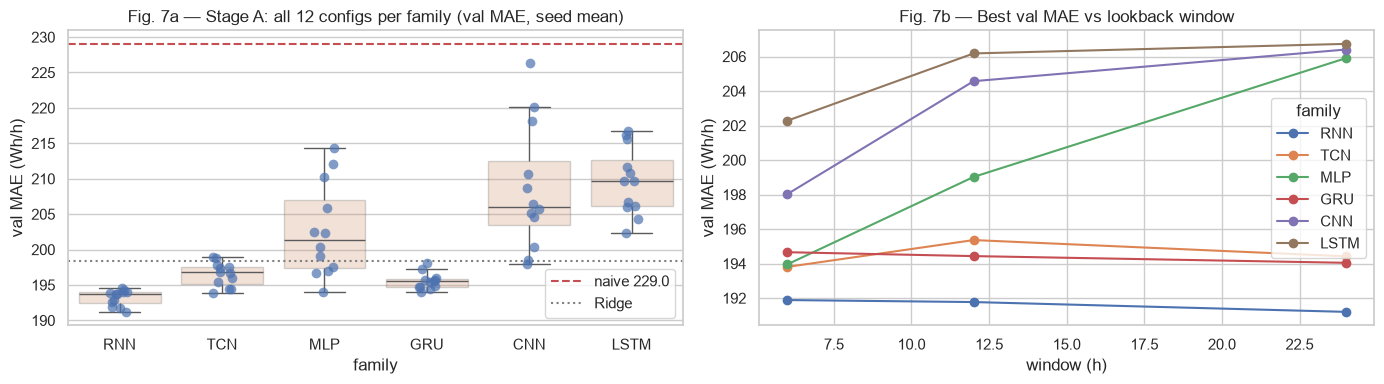

Selected family for Stage B (lowest Stage-A objective): RNN  cfg={'window': 24, 'hidden': 64, 'layers': 2}  val MAE 191.20 ± 0.85; runner-up TCN 193.81 ± 0.36


In [16]:
agg_A = (screen.groupby(["family", "cfg_id", "cfg"])
               .agg(window=("window", "first"), val_MAE=("val_MAE", "mean"), val_MAE_std=("val_MAE", "std"), val_RMSE=("val_RMSE", "mean"),
                    params=("params", "first"), epochs=("epochs", "mean"), train_s=("train_s", "mean"))
               .reset_index().fillna({"val_MAE_std": 0.0}))
agg_A.to_csv("results_stage2/stageA_configs.csv", index=False)
BEST_A = {}; best_rows = []
for name in GRID_A:
    sub = agg_A[agg_A.family == name].sort_values("val_MAE")
    BEST_A[name] = json.loads(sub.iloc[0].cfg); best_rows.append(sub.iloc[0])
best_A = pd.DataFrame(best_rows).sort_values("val_MAE").reset_index(drop=True)
best_A["val_MAE_impr_vs_naive_%"] = 100 * (BASE_VAL["MAE"] - best_A.val_MAE) / BASE_VAL["MAE"]
print(f"Table 5 — Stage A: best configuration per family (validation, mean over seeds {SCREEN_SEEDS}); naive val MAE = {BASE_VAL['MAE']:.2f}")
display(best_A.drop(columns=["cfg_id"]).round(3))
json.dump(BEST_A, open("results_stage2/stageA_best_configs.json", "w"), indent=1)

order = best_A.family.tolist()
fig, axs = plt.subplots(1, 2, figsize=(14, 4))
sns.stripplot(data=agg_A, x="family", y="val_MAE", order=order, ax=axs[0], size=7, alpha=0.7)
sns.boxplot(data=agg_A, x="family", y="val_MAE", order=order, ax=axs[0], showfliers=False, boxprops=dict(alpha=0.25))
axs[0].axhline(BASE_VAL["MAE"], color="r", ls="--", label=f"naive {BASE_VAL['MAE']:.1f}")
axs[0].axhline(metrics(Y_val, ridge_pred["val"])["MAE"], color="gray", ls=":", label="Ridge")
axs[0].set_title("Fig. 7a — Stage A: all 12 configs per family (val MAE, seed mean)"); axs[0].set_ylabel("val MAE (Wh/h)"); axs[0].legend()
wb = agg_A.groupby(["family", "window"]).val_MAE.min().unstack(0)[order]
wb.plot(marker="o", ax=axs[1]); axs[1].set_title("Fig. 7b — Best val MAE vs lookback window"); axs[1].set_xlabel("window (h)"); axs[1].set_ylabel("val MAE (Wh/h)")
plt.tight_layout(); plt.savefig("results_stage2/fig7_stageA.png", dpi=150); plt.show()

FINAL_FAMILY = best_A.family.iloc[0]
print(f"Selected family for Stage B (lowest Stage-A objective): {FINAL_FAMILY}  cfg={BEST_A[FINAL_FAMILY]}  "
      f"val MAE {best_A.val_MAE.iloc[0]:.2f} ± {best_A.val_MAE_std.iloc[0]:.2f}; runner-up {best_A.family.iloc[1]} {best_A.val_MAE.iloc[1]:.2f} ± {best_A.val_MAE_std.iloc[1]:.2f}")

### 8.2 Stage B — random-search HPO of the selected family (validation only)
Trial 0 re-scores the Stage-A winner with all defaults made explicit (anchor), so Stage B can only keep or improve on it.

In [17]:
rng = np.random.default_rng(SEED)
def sample_cfg(family):
    cfg = {}
    for k, v in {**SPACE_B_COMMON, **SPACE_B_ARCH[family]}.items():
        if isinstance(v, tuple) and v[0] == "log-uniform":
            cfg[k] = float(f"{np.exp(rng.uniform(np.log(v[1]), np.log(v[2]))):.2g}")
        else:
            cfg[k] = v[rng.integers(len(v))]
    return to_native(cfg)

anchor = to_native(full_cfg(BEST_A[FINAL_FAMILY]))
trial_cfgs, seen = [anchor], {json.dumps(anchor, sort_keys=True)}
while len(trial_cfgs) < N_TRIALS_B:
    c_ = sample_cfg(FINAL_FAMILY); key = json.dumps(c_, sort_keys=True)
    if key not in seen: seen.add(key); trial_cfgs.append(c_)

trial_rows = []; t_all = time.time()
for ti, cfg in enumerate(trial_cfgs):
    res = [run_config(FINAL_FAMILY, cfg, s) for s in SCREEN_SEEDS]
    v = [r["val"]["MAE"] for r in res]
    trial_rows.append(dict(trial=ti, **cfg, val_MAE=np.mean(v), val_MAE_std=np.std(v), val_RMSE=np.mean([r["val"]["RMSE"] for r in res]),
                           params=res[0]["params"], epochs=np.mean([r["epochs"] for r in res]), train_s=np.mean([r["train_time"] for r in res])))
    print(f"trial {ti:2d} {cfg} -> {np.mean(v):7.2f} ± {np.std(v):5.2f}")
trials = pd.DataFrame(trial_rows); trials.to_csv("results_stage2/stageB_trials.csv", index=False)
print(f"Stage B finished in {(time.time()-t_all)/60:.1f} min")
print(f"Table 6 — Stage B trials for {FINAL_FAMILY} (top 10 by val MAE)"); display(trials.sort_values("val_MAE").head(10).round(4))

trial  0 {'dropout': 0.2, 'lr': 0.001, 'batch': 64, 'wd': 1e-05, 'loss': 'L1', 'window': 24, 'hidden': 64, 'layers': 2} ->  191.20 ±  0.60
trial  1 {'window': 3, 'dropout': 0.3, 'lr': 0.00044, 'batch': 64, 'wd': 0.0001, 'loss': 'L1', 'hidden': 64, 'layers': 1} ->  195.17 ±  0.43
trial  2 {'window': 3, 'dropout': 0.2, 'lr': 0.0013, 'batch': 128, 'wd': 0.0001, 'loss': 'Huber', 'hidden': 64, 'layers': 1} ->  195.90 ±  0.51
trial  3 {'window': 24, 'dropout': 0.1, 'lr': 0.00035, 'batch': 32, 'wd': 0.0001, 'loss': 'Huber', 'hidden': 64, 'layers': 2} ->  194.63 ±  3.31
trial  4 {'window': 24, 'dropout': 0.2, 'lr': 0.00022, 'batch': 64, 'wd': 0.0, 'loss': 'Huber', 'hidden': 128, 'layers': 1} ->  193.70 ±  1.38
trial  5 {'window': 24, 'dropout': 0.3, 'lr': 0.00086, 'batch': 32, 'wd': 0.0001, 'loss': 'Huber', 'hidden': 32, 'layers': 1} ->  193.41 ±  2.56
trial  6 {'window': 24, 'dropout': 0.1, 'lr': 0.0014, 'batch': 128, 'wd': 0.0001, 'loss': 'L1', 'hidden': 32, 'layers': 2} ->  193.71 ±  0.28
t

,trial,dropout,lr,batch,wd,loss,window,hidden,layers,val_MAE,val_MAE_std,val_RMSE,params,epochs,train_s
14,14,0.0,0.0010,32,0.0000,L1,3,128,2,188.9599,2.3061,370.5334,54401,40.5,5.9509
8,8,0.1,0.0004,32,0.0000,L1,24,128,1,190.4952,1.0559,379.3719,21377,40.0,11.2852
9,9,0.0,0.0005,32,0.0000,Huber,6,64,3,190.8906,2.9144,369.9494,23233,24.5,6.3985
0,0,0.2,0.0010,64,0.0000,L1,24,64,2,191.2020,0.6014,384.4497,14913,45.5,17.6145
10,10,0.0,0.0011,128,0.0000,L1,6,128,3,191.5461,0.2695,382.3999,87425,29.5,3.1216
18,18,0.1,0.0007,64,0.0000,Huber,6,128,2,191.6507,0.3285,365.8536,54401,35.0,4.7116
27,27,0.2,0.0004,32,0.0000,L1,6,64,1,192.3825,0.1173,387.9445,6593,45.5,5.0862
24,24,0.1,0.0011,128,0.0001,L1,24,64,1,192.9845,1.5188,386.9885,6593,37.0,4.5791
5,5,0.3,0.0009,32,0.0001,Huber,24,32,1,193.4053,2.5563,377.2183,2273,45.5,7.6681
4,4,0.2,0.0002,64,0.0000,Huber,24,128,1,193.7035,1.3777,371.2465,21377,47.0,7.6349


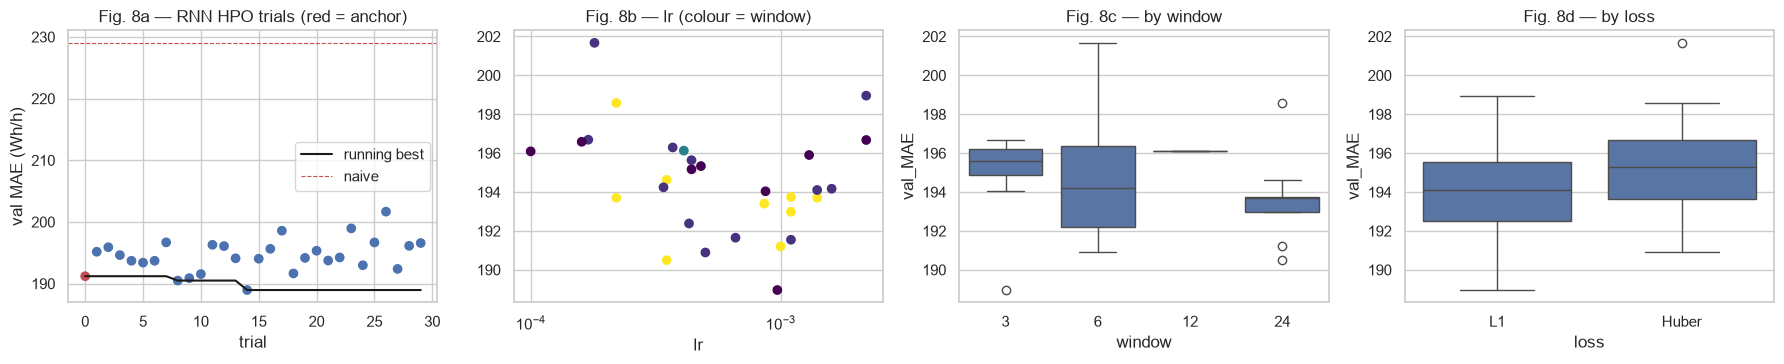

In [18]:
fig, axs = plt.subplots(1, 4, figsize=(18, 3.8))
axs[0].scatter(trials.trial, trials.val_MAE, c=["r" if t == 0 else "C0" for t in trials.trial])
axs[0].plot(trials.trial, trials.val_MAE.cummin(), color="k", label="running best"); axs[0].axhline(BASE_VAL["MAE"], color="r", ls="--", lw=0.8, label="naive")
axs[0].set_title(f"Fig. 8a — {FINAL_FAMILY} HPO trials (red = anchor)"); axs[0].set_xlabel("trial"); axs[0].set_ylabel("val MAE (Wh/h)"); axs[0].legend()
axs[1].scatter(trials.lr, trials.val_MAE, c=trials.window, cmap="viridis"); axs[1].set_xscale("log"); axs[1].set_title("Fig. 8b — lr (colour = window)"); axs[1].set_xlabel("lr")
sns.boxplot(data=trials, x="window", y="val_MAE", ax=axs[2]); axs[2].set_title("Fig. 8c — by window")
sns.boxplot(data=trials, x="loss", y="val_MAE", ax=axs[3]); axs[3].set_title("Fig. 8d — by loss")
plt.tight_layout(); plt.savefig("results_stage2/fig8_stageB.png", dpi=150); plt.show()

## 9. Model selection and checkpoint (before touching the test set)
Rule (declared in §8): take the best Stage-B objective; among trials within one seed-std of it, prefer the fewest parameters. The finalist is then retrained with seed 42 and saved together with its configuration and the complete preprocessing state.

In [19]:
best_t = trials.sort_values("val_MAE").iloc[0]
tol = best_t.val_MAE + best_t.val_MAE_std
cands = trials[trials.val_MAE <= tol].sort_values(["params", "val_MAE"])
sel = cands.iloc[0]
cfg_keys = list(SPACE_B_COMMON) + list(SPACE_B_ARCH[FINAL_FAMILY])
FINAL_CFG = to_native({k: sel[k] for k in cfg_keys})
for k in ("window", "hidden", "layers", "filters", "kernel", "channels", "batch"):
    if k in FINAL_CFG: FINAL_CFG[k] = int(FINAL_CFG[k])
anc = trials[trials.trial == 0].iloc[0]
print(f"Best trial #{int(best_t.trial)}: val MAE {best_t.val_MAE:.2f} ± {best_t.val_MAE_std:.2f}; {len(cands)} trial(s) within 1 std (≤ {tol:.2f})")
print(f"Selected trial #{int(sel.trial)} ({int(sel.params)} params): val MAE {sel.val_MAE:.2f} ± {sel.val_MAE_std:.2f}")
print(f"Anchor (Stage-A config): {anc.val_MAE:.2f} ± {anc.val_MAE_std:.2f}  -> tuning gain {anc.val_MAE - sel.val_MAE:+.2f} Wh/h "
      f"({'larger than' if anc.val_MAE - sel.val_MAE > max(anc.val_MAE_std, sel.val_MAE_std) else 'within'} seed noise)")
print("FINAL:", FINAL_FAMILY, FINAL_CFG)

sel_table = pd.DataFrame([dict(candidate=f"{r.family} (Stage A)", val_MAE=r.val_MAE, val_MAE_std=r.val_MAE_std, params=r.params) for r in best_A.itertuples()]
                         + [dict(candidate=f"{FINAL_FAMILY} ★ tuned (trial {int(sel.trial)})", val_MAE=sel.val_MAE, val_MAE_std=sel.val_MAE_std, params=sel.params)])
print("Table 7 — Selection evidence (validation only)"); display(sel_table.sort_values("val_MAE").round(3))

r_fin = run_config(FINAL_FAMILY, FINAL_CFG, SEED)
torch.save(dict(family=FINAL_FAMILY, config=FINAL_CFG, state_dict=r_fin["model"].state_dict(), C=C, feat_cols=feat_cols, horizon=HORIZON,
                freq=FREQ, maxw=MAXW, seed=SEED, val_metrics=r_fin["val"], env=ENV), "checkpoints/stage2_finalist.pt")
pickle.dump(dict(imputer=imputer, x_scaler=x_scaler, y_scaler=y_scaler, feat_cols=feat_cols, log_cols=LOG_COLS, drop=DROP,
                 target_transform="log1p -> StandardScaler", resample=dict(freq=FREQ, energy_sum=ENERGY, others="mean", full_bin=STEPS_PER_BIN),
                 calendar=["hour_sin", "hour_cos", "dow_sin", "dow_cos", "weekend"]), open("checkpoints/stage2_preprocessing.pkl", "wb"))
json.dump(dict(family=FINAL_FAMILY, config=FINAL_CFG, selected_trial=int(sel.trial), val_MAE_mean=float(sel.val_MAE),
               val_MAE_std=float(sel.val_MAE_std), seed=SEED, protocol="results_stage2/hpo_protocol.json"),
          open("checkpoints/stage2_finalist_config.json", "w"), indent=1)
print(f"Checkpoint saved (seed {SEED}, val MAE {r_fin['val']['MAE']:.2f}, {r_fin['params']} params): checkpoints/stage2_finalist.pt, "
      "stage2_preprocessing.pkl, stage2_finalist_config.json")

Best trial #14: val MAE 188.96 ± 2.31; 4 trial(s) within 1 std (≤ 191.27)
Selected trial #0 (14913 params): val MAE 191.20 ± 0.60
Anchor (Stage-A config): 191.20 ± 0.60  -> tuning gain +0.00 Wh/h (within seed noise)
FINAL: RNN {'window': 24, 'dropout': 0.2, 'lr': 0.001, 'batch': 64, 'wd': 1e-05, 'loss': 'L1', 'hidden': 64, 'layers': 2}
Table 7 — Selection evidence (validation only)


,candidate,val_MAE,val_MAE_std,params
0,RNN (Stage A),191.202,0.851,14913
6,RNN ★ tuned (trial 0),191.202,0.601,14913
1,TCN (Stage A),193.808,0.360,4705
2,MLP (Stage A),193.955,3.355,16001
3,GRU (Stage A),194.046,3.261,44609
4,CNN (Stage A),198.026,8.763,11633
5,LSTM (Stage A),202.281,2.918,8993


Checkpoint saved (seed 42, val MAE 191.80, 14913 params): checkpoints/stage2_finalist.pt, stage2_preprocessing.pkl, stage2_finalist_config.json


## 10. Final evaluation on the test set
The test split is used here for the first time. Each family is retrained with **5 seeds** using its Stage-A best configuration; the finalist family is reported twice (Stage-A config and tuned config). For the finalist, seed 42 is the **loaded checkpoint** rather than a retrain. Inference time is the mean over the 658 test windows (batched) and single-sample latency (batch = 1) on the seed-42 model.

In [20]:
ckpt = torch.load("checkpoints/stage2_finalist.pt", map_location=DEVICE, weights_only=False)
FINAL_LABEL = f"{FINAL_FAMILY} ★ tuned"
entries = [(f, f, BEST_A[f]) for f in GRID_A] + [(FINAL_LABEL, FINAL_FAMILY, ckpt["config"])]
final, run_log, test_preds, curves, infer = {}, [], {}, {}, {}
for label, fam, cfg in entries:
    L = cfg["window"]; per_seed = []
    for s in FINAL_SEEDS:
        if label == FINAL_LABEL and s == SEED:
            m = build(fam, cfg); m.load_state_dict(ckpt["state_dict"])
            r = dict(model=m, hist=r_fin["hist"], train_time=r_fin["train_time"], epochs=r_fin["epochs"], params=n_params(m),
                     val=metrics(Y_val, inv(predict_scaled(m, tens(L, "val")[0]))))
        else:
            r = run_config(fam, cfg, s)
        pt = inv(predict_scaled(r["model"], tens(L, "test")[0])); mt = metrics(Y_test, pt)
        if s == SEED:
            test_preds[label] = pt; curves[label] = r["hist"]; infer[label] = infer_time(r["model"], tens(L, "test")[0])
        per_seed.append(dict(seed=s, params=r["params"], train_s=r["train_time"], epochs=r["epochs"],
                             **{f"val_{k}": v for k, v in r["val"].items()}, **{f"test_{k}": v for k, v in mt.items()}))
        run_log.append(dict(model=label, cfg=cfg, **per_seed[-1]))
    final[label] = pd.DataFrame(per_seed)
    print(f"{label:12s} test MAE {final[label].test_MAE.mean():7.2f} ± {final[label].test_MAE.std(ddof=0):5.2f}")
FINAL_TEST_PRED = test_preds[FINAL_LABEL]

MLP          test MAE  188.78 ±  3.18
CNN          test MAE  205.91 ±  5.77
RNN          test MAE  184.60 ±  1.74
LSTM         test MAE  214.95 ± 10.21
GRU          test MAE  194.67 ±  2.31
TCN          test MAE  194.01 ± 10.64
RNN ★ tuned  test MAE  184.60 ±  1.74


In [21]:
BASE_TEST = metrics(Y_test, base[NAIVE]["test"])
rows = []
for k in base:
    mv, mt = metrics(Y_val, base[k]["val"]), metrics(Y_test, base[k]["test"])
    rows.append(dict(Model=k, Config="—", Params=0, Train_s=0.0, Infer_ms_batched=np.nan, Infer_ms_single=np.nan, Seeds="—", val_MAE=mv["MAE"],
                     **{f"test_{m}": mt[m] for m in mt}, test_MAE_std=0.0, test_RMSE_std=0.0))
mv, mt = metrics(Y_val, ridge_pred["val"]), metrics(Y_test, ridge_pred["test"])
Xr_ = get_data(R_L)["test"]["X"].reshape(len(T_test), -1); t0 = time.time(); ridge.predict(Xr_); r_inf = (time.time() - t0) / len(T_test) * 1e3
rows.append(dict(Model="Ridge (log target)", Config=f"L={R_L}, alpha={R_ALPHA}", Params=ridge_params, Train_s=ridge_time, Infer_ms_batched=r_inf,
                 Infer_ms_single=np.nan, Seeds="deterministic", val_MAE=mv["MAE"], **{f"test_{m}": mt[m] for m in mt}, test_MAE_std=0.0, test_RMSE_std=0.0))
for label, f in final.items():
    cfg = next(c for l_, _, c in entries if l_ == label)
    rows.append(dict(Model=label, Config=json.dumps(cfg), Params=int(f.params.iloc[0]), Train_s=f.train_s.mean(),
                     Infer_ms_batched=infer[label][0], Infer_ms_single=infer[label][1], Seeds=str(FINAL_SEEDS), val_MAE=f.val_MAE.mean(),
                     **{f"test_{m}": f[f"test_{m}"].mean() for m in ("MAE", "RMSE", "sMAPE", "R2")},
                     test_MAE_std=f.test_MAE.std(ddof=0), test_RMSE_std=f.test_RMSE.std(ddof=0)))
cmp_ = pd.DataFrame(rows)
cmp_["MAE_improv_%"] = 100 * (BASE_TEST["MAE"] - cmp_["test_MAE"]) / BASE_TEST["MAE"]
cmp_["RMSE_improv_%"] = 100 * (BASE_TEST["RMSE"] - cmp_["test_RMSE"]) / BASE_TEST["RMSE"]
cmp_.to_csv("results_stage2/table8_comparison.csv", index=False)
json.dump(dict(env=ENV, seed=SEED, final_seeds=FINAL_SEEDS, horizon=HORIZON, freq=FREQ, runs=run_log),
          open("results_stage2/run_log.json", "w"), indent=1, default=float)

pm = lambda a, s: f"{a:.2f} ± {s:.2f}" if s > 0 else f"{a:.2f}"
pretty = pd.DataFrame({
    "Model": cmp_.Model, "Params": cmp_.Params, "Train (s)": cmp_.Train_s.round(1),
    "Infer ms/sample (batched)": cmp_.Infer_ms_batched.round(4), "Latency ms (batch=1)": cmp_.Infer_ms_single.round(3),
    "Val MAE": cmp_.val_MAE.round(2),
    "Test MAE": [pm(a, s) for a, s in zip(cmp_.test_MAE, cmp_.test_MAE_std)],
    "Test RMSE": [pm(a, s) for a, s in zip(cmp_.test_RMSE, cmp_.test_RMSE_std)],
    "sMAPE %": cmp_.test_sMAPE.round(1), "R²": cmp_.test_R2.round(3),
    "MAE impr. vs naive %": cmp_["MAE_improv_%"].round(1), "RMSE impr. vs naive %": cmp_["RMSE_improv_%"].round(1)})
print(f"Table 8 — TEST-SET COMPARISON (Wh/h; same {len(T_test)} test hours for every model; neural rows = mean ± std over {len(FINAL_SEEDS)} seeds)")
display(pretty)

Table 8 — TEST-SET COMPARISON (Wh/h; same 658 test hours for every model; neural rows = mean ± std over 5 seeds)


,Model,Params,Train (s),Infer ms/sample (batched),Latency ms (batch=1),Val MAE,Test MAE,Test RMSE,sMAPE %,R²,MAE impr. vs naive %,RMSE impr. vs naive %
0,Naive (last hour),0,0.0,NaN,NaN,229.04,198.83,372.23,25.8,0.225,0.0,0.0
1,Seasonal naive (t-24 h),0,0.0,NaN,NaN,306.61,265.47,485.42,34.4,-0.318,-33.5,-30.4
2,Hour-of-week median (train),0,0.0,NaN,NaN,264.77,246.29,438.54,35.0,-0.076,-23.9,-17.8
3,Ridge (log target),109,0.0,0.0000,NaN,198.42,182.17,339.46,25.4,0.356,8.4,8.8
4,MLP,16001,2.0,0.0006,0.074,193.05,188.78 ± 3.18,368.06 ± 11.65,26.3,0.242,5.1,1.1
5,CNN,11633,3.5,0.0018,0.206,200.42,205.91 ± 5.77,390.20 ± 14.06,29.3,0.147,-3.6,-4.8
6,RNN,14913,14.0,0.0081,0.561,191.14,184.60 ± 1.74,364.32 ± 6.30,25.5,0.257,7.2,2.1
7,LSTM,8993,4.9,0.0034,0.359,202.84,214.95 ± 10.21,421.52 ± 15.21,30.7,0.005,-8.1,-13.2
8,GRU,44609,18.8,0.0227,1.416,194.63,194.67 ± 2.31,386.86 ± 6.08,27.0,0.163,2.1,-3.9
9,TCN,4705,8.5,0.0087,0.413,197.38,194.01 ± 10.64,378.13 ± 15.07,27.6,0.199,2.4,-1.6


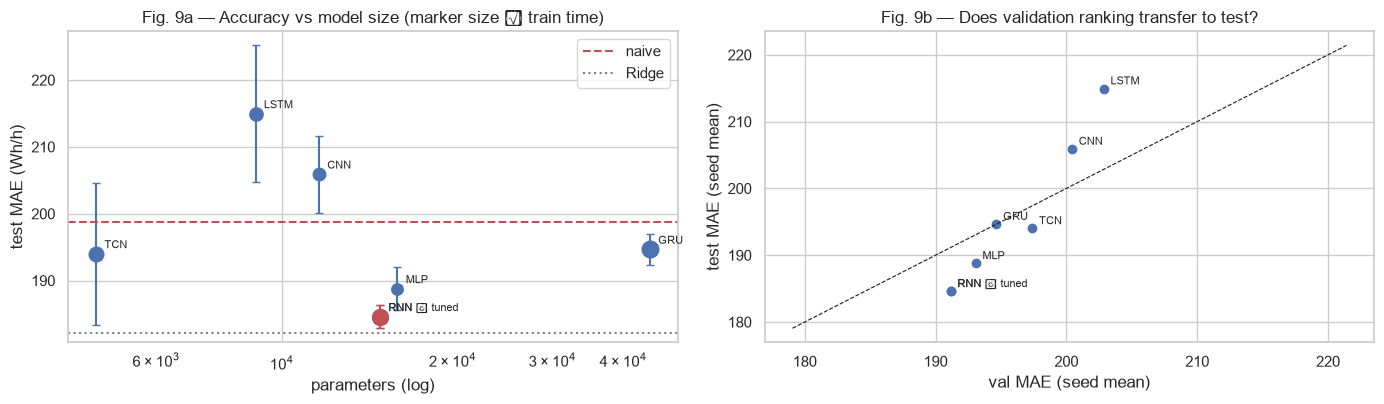

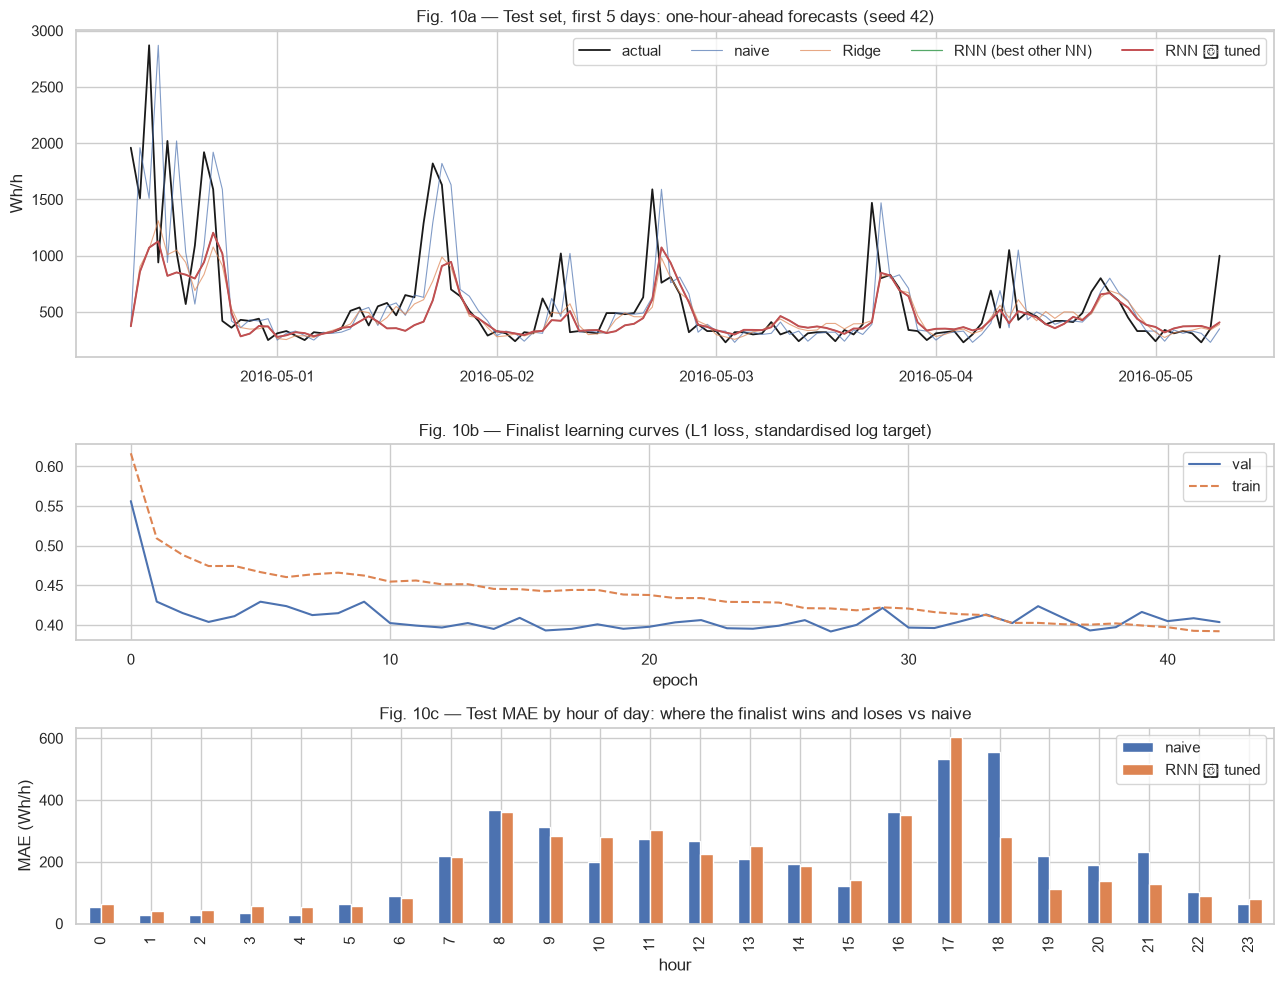

In [22]:
nn_rows = cmp_[cmp_.Model.isin(final.keys())]
fig, axs = plt.subplots(1, 2, figsize=(14, 4.2))
for _, r in nn_rows.iterrows():
    axs[0].errorbar(r.Params, r.test_MAE, yerr=r.test_MAE_std, fmt="o", ms=6 + 2*np.log1p(r.Train_s), capsize=3,
                    color="C3" if r.Model == FINAL_LABEL else "C0")
    axs[0].annotate(r.Model, (r.Params, r.test_MAE), textcoords="offset points", xytext=(6, 4), fontsize=8)
axs[0].axhline(BASE_TEST["MAE"], color="r", ls="--", label="naive"); axs[0].axhline(metrics(Y_test, ridge_pred["test"])["MAE"], color="gray", ls=":", label="Ridge")
axs[0].set_xscale("log"); axs[0].set_xlabel("parameters (log)"); axs[0].set_ylabel("test MAE (Wh/h)"); axs[0].legend()
axs[0].set_title("Fig. 9a — Accuracy vs model size (marker size ∝ train time)")
axs[1].scatter(nn_rows.val_MAE, nn_rows.test_MAE)
for _, r in nn_rows.iterrows(): axs[1].annotate(r.Model, (r.val_MAE, r.test_MAE), textcoords="offset points", xytext=(5, 3), fontsize=8)
lim = [min(nn_rows.val_MAE.min(), nn_rows.test_MAE.min()) * 0.97, max(nn_rows.val_MAE.max(), nn_rows.test_MAE.max()) * 1.03]
axs[1].plot(lim, lim, "k--", lw=0.8); axs[1].set_xlabel("val MAE (seed mean)"); axs[1].set_ylabel("test MAE (seed mean)")
axs[1].set_title("Fig. 9b — Does validation ranking transfer to test?")
plt.tight_layout(); plt.savefig("results_stage2/fig9_cost_and_transfer.png", dpi=150); plt.show()

others = nn_rows[nn_rows.Model != FINAL_LABEL].sort_values("test_MAE").Model.iloc[0]
fig, axs = plt.subplots(3, 1, figsize=(13, 10), gridspec_kw=dict(height_ratios=[2, 1.2, 1.2]))
sl = slice(0, 5*DAY); tt = dh.date.values[T_test][sl]
axs[0].plot(tt, Y_test[sl], color="k", lw=1.3, label="actual")
axs[0].plot(tt, base[NAIVE]["test"][sl], lw=0.8, alpha=0.7, label="naive")
axs[0].plot(tt, ridge_pred["test"][sl], lw=0.8, alpha=0.7, label="Ridge")
axs[0].plot(tt, test_preds[others][sl], lw=0.9, label=f"{others} (best other NN)")
axs[0].plot(tt, FINAL_TEST_PRED[sl], lw=1.4, color="C3", label=FINAL_LABEL)
axs[0].set_title("Fig. 10a — Test set, first 5 days: one-hour-ahead forecasts (seed 42)"); axs[0].set_ylabel("Wh/h"); axs[0].legend(ncol=5)
h_ = curves[FINAL_LABEL]
axs[1].plot([v for _, v in h_], label="val"); axs[1].plot([t for t, _ in h_], ls="--", label="train")
axs[1].set_title(f"Fig. 10b — Finalist learning curves ({ckpt['config']['loss']} loss, standardised log target)"); axs[1].set_xlabel("epoch"); axs[1].legend()
err_df = pd.DataFrame(dict(hour=dh.date.dt.hour.values[T_test], fin=np.abs(FINAL_TEST_PRED - Y_test), naive=np.abs(base[NAIVE]["test"] - Y_test)))
err_df.groupby("hour")[["naive", "fin"]].mean().rename(columns={"fin": FINAL_LABEL}).plot(kind="bar", ax=axs[2])
axs[2].set_title("Fig. 10c — Test MAE by hour of day: where the finalist wins and loses vs naive"); axs[2].set_ylabel("MAE (Wh/h)")
plt.tight_layout(); plt.savefig("results_stage2/fig10_forecasts.png", dpi=150); plt.show()

## 11. Reproducibility smoke test
Reloads the checkpoint and the pickled preprocessing state, rebuilds features **from the raw hourly table** (not from cached arrays), and checks the predictions match the stored finalist test predictions. Runs in seconds; with `QUICK=1` the whole notebook runs end-to-end in a few minutes.

In [23]:
ck = torch.load("checkpoints/stage2_finalist.pt", map_location=DEVICE, weights_only=False)
pp = pickle.load(open("checkpoints/stage2_preprocessing.pkl", "rb"))
m2 = build(ck["family"], ck["config"]); m2.load_state_dict(ck["state_dict"])
Xr2 = dh[pp["feat_cols"]].copy()
for c in pp["log_cols"]: Xr2[c] = np.log1p(Xr2[c])
A2 = np.hstack([pp["x_scaler"].transform(pp["imputer"].transform(Xr2)), cal]).astype(np.float32)
L2 = ck["config"]["window"]; Ts = T_test[:50]; idx = (Ts - ck["horizon"])[:, None] + np.arange(-L2 + 1, 1)[None, :]
X2 = np.concatenate([A2[idx], np.repeat(cal[Ts][:, None, :], L2, axis=1)], axis=2).astype(np.float32)
p2 = np.clip(np.expm1(pp["y_scaler"].inverse_transform(predict_scaled(m2, torch.from_numpy(X2).to(DEVICE)).reshape(-1, 1)).ravel()), 0, None)
assert np.allclose(p2, FINAL_TEST_PRED[:50], rtol=1e-3, atol=1e-2), np.abs(p2 - FINAL_TEST_PRED[:50]).max()
print(f"Smoke test passed ✔  {ck['family']} {ck['config']} reproduces stored predictions (max |Δ| = {np.abs(p2 - FINAL_TEST_PRED[:50]).max():.2e} Wh/h)")

Smoke test passed ✔  RNN {'window': 24, 'dropout': 0.2, 'lr': 0.001, 'batch': 64, 'wd': 1e-05, 'loss': 'L1', 'hidden': 64, 'layers': 2} reproduces stored predictions (max |Δ| = 3.74e-04 Wh/h)


## 12. Results summary (auto-generated from the run above)

In [24]:
fr = cmp_[cmp_.Model == FINAL_LABEL].iloc[0]; rr = cmp_[cmp_.Model.str.startswith("Ridge")].iloc[0]
rank = cmp_.sort_values("test_MAE").Model.tolist()
print(f"Target: next-hour appliance energy (Wh/h), log1p-trained. Test hours: {len(T_test)} ({dh.date[T_test[0]].date()} → {dh.date[T_test[-1]].date()})")
print(f"Naive test MAE {BASE_TEST['MAE']:.2f} / RMSE {BASE_TEST['RMSE']:.2f}")
print(f"Finalist {FINAL_LABEL} {ckpt['config']}: test MAE {fr.test_MAE:.2f} ± {fr.test_MAE_std:.2f} ({fr['MAE_improv_%']:+.1f}% vs naive), "
      f"RMSE {fr.test_RMSE:.2f} ± {fr.test_RMSE_std:.2f} ({fr['RMSE_improv_%']:+.1f}%), {int(fr.Params)} params, {fr.Train_s:.1f} s train, "
      f"{fr.Infer_ms_single:.3f} ms latency")
print(f"Ridge: test MAE {rr.test_MAE:.2f} ({rr['MAE_improv_%']:+.1f}%), RMSE {rr.test_RMSE:.2f} ({rr['RMSE_improv_%']:+.1f}%)")
print("Ranking by test MAE:", " > ".join(rank))
nn_val_rank = cmp_[cmp_.Model.isin(final.keys())].sort_values("val_MAE").Model.tolist()
nn_test_rank = cmp_[cmp_.Model.isin(final.keys())].sort_values("test_MAE").Model.tolist()
print("NN ranking (val):", nn_val_rank, "\nNN ranking (test):", nn_test_rank)

Target: next-hour appliance energy (Wh/h), log1p-trained. Test hours: 658 (2016-04-30 → 2016-05-27)
Naive test MAE 198.83 / RMSE 372.23
Finalist RNN ★ tuned {'window': 24, 'dropout': 0.2, 'lr': 0.001, 'batch': 64, 'wd': 1e-05, 'loss': 'L1', 'hidden': 64, 'layers': 2}: test MAE 184.60 ± 1.74 (+7.2% vs naive), RMSE 364.32 ± 6.30 (+2.1%), 14913 params, 12.1 s train, 0.551 ms latency
Ridge: test MAE 182.17 (+8.4%), RMSE 339.46 (+8.8%)
Ranking by test MAE: Ridge (log target) > RNN > RNN ★ tuned > MLP > TCN > GRU > Naive (last hour) > CNN > LSTM > Hour-of-week median (train) > Seasonal naive (t-24 h)
NN ranking (val): ['RNN', 'RNN ★ tuned', 'MLP', 'GRU', 'TCN', 'CNN', 'LSTM'] 
NN ranking (test): ['RNN', 'RNN ★ tuned', 'MLP', 'TCN', 'GRU', 'CNN', 'LSTM']


## 13. Conclusions and risks for Stage 3
*Write these from the outputs above — every number should be traceable to Table 8 / Figs. 7–10.*

1. **Target redesign.** State the Table 1 result: at 10 min nothing beats persistence on MAE; hourly + log1p is the design where learned models have signal beyond naive. Compare the % improvement over naive with Stage 1 (−18.5% MAE for the best Stage 1 network).
2. **Controlled comparison.** Which family won Stage A, by how much, and is the gap larger than the seed std (Table 5, Fig. 7a)? Which window was preferred (Fig. 7b)?
3. **HPO.** Did Stage B improve on the anchor beyond seed noise (Table 7, Fig. 8a)? Which hyperparameters mattered (Fig. 8b–d)?
4. **Selection vs test.** Did the validation ranking hold on test (Fig. 9b)? Accuracy–cost trade-off (Fig. 9a, latency column).
5. **Where it fails.** Fig. 10c: hours where the finalist is worse than naive (typically sudden evening peaks), and Fig. 10a: lag behind spikes.
6. **Risks / next steps (Stage 3).** Short record (~4.5 months, ~1,950 training hours) and warmer test period; add the Transformer under the same protocol; failure-regime and uncertainty analysis (e.g. empirical error bands from seed spread / residual quantiles); optional Jetson deployment of the checkpoint.